Select the kernel or interpreter associated with ~/sales-dashboard/.venv. At the top right corner.



Verify that the notebook runs inside WSL, not a Windows Python installation.

In [15]:
import sys
import os

print(f"Python Executable: {sys.executable}")
print(f"Operating System: {os.name} ({sys.platform})")


Python Executable: /mnt/d/DS_Course/11.Career_prep/To_Job/Projects/Data_Analyst/Sales_Dashboard/.venv/bin/python
Operating System: posix (linux)


2. Load the CSV and show the first five records.

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.home() / "/mnt/d/DS_Course/11.Career_prep/To_Job/Projects/Data_Analyst/Sales_Dashboard"
DATA_PATH = PROJECT_DIR / "data/raw" / "sales_data.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9800, 17)


,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,CA-2017-138688,12/6/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


3. Inspect the column names and data types:

In [57]:
print("Columns:", df.columns.tolist())

print("\nData types:\n", df.dtypes)

print("\nDataset information:", df.info())

Columns: ['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']

Data types:
 Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   

4. Inspect numerical and categorical fields:

What to learn:
* How many rows and columns the dataset contains.

* Whether numeric fields have been imported as numbers.

* Whether date fields are strings or dates.

* Whether any columns are unnecessary.

* Whether the data contains unexpected values.

In [18]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order ID,9800,4922,CA-2018-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order Date,9800,1230,5/9/2017,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Date,9800,1326,26/09/2018,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ship Mode,9800,4,Standard Class,5859,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer ID,9800,793,WB-21850,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Name,9800,793,William Brown,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Segment,9800,3,Consumer,5101,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,9800,1,United States,9800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,9800,529,New York City,891,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,9800,49,California,1946,NaN,NaN,NaN,NaN,NaN,NaN,NaN


5. Perform data quality checks

 Examine missing values, duplicate rows, unique values.
 
 Check whether the column names contain extra spaces and remove an unnecessary unnamed column if present:

In [19]:
# Missing values
missing = df.isna().sum().sort_values(ascending=False)

display(
    missing[missing > 0].to_frame("missing_count")
)

# Exact duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Unique values in important columns
for col in ["Order ID", "Customer ID", "Category", "Region"]:
    if col in df.columns:
        print(f"{col}: {df[col].nunique()} unique values")

df. columns = df.columns.str.strip()

unnamed_cols = [
    col for col in df.columns
    if col.lower().startswith("unnamed")
]

df = df.drop(columns=unnamed_cols)

print("Shape after removing unnamed columns:", df.shape)

,missing_count
Postal Code,11


Duplicate rows: 1
Order ID: 4922 unique values
Customer ID: 793 unique values
Category: 3 unique values
Region: 4 unique values
Shape after removing unnamed columns: (9800, 17)


6. Clean and validate data types:



In [20]:
print(df[["Order Date", "Ship Date"]].head(10))



   Order Date   Ship Date
0   8/11/2017  11/11/2017
1   8/11/2017  11/11/2017
2   12/6/2017  16/06/2017
3  11/10/2016  18/10/2016
4  11/10/2016  18/10/2016
5    9/6/2015  14/06/2015
6    9/6/2015  14/06/2015
7    9/6/2015  14/06/2015
8    9/6/2015  14/06/2015
9    9/6/2015  14/06/2015


In [56]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], dayfirst=True, errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], dayfirst=True, errors="coerce"
)

df["Postal Code"] = df["Postal Code"].astype(str)



Validate the conversion:

In [23]:
print("Invalid order dates:", df["Order Date"].isna().sum())
print("Invalid ship dates:", df["Ship Date"].isna().sum())

print(
    "Orders shipped before order date:",
    (df["Ship Date"] < df["Order Date"]).sum()
)

Invalid order dates: 0
Invalid ship dates: 0
Orders shipped before order date: 0


Inspect the sales column:


In [24]:
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

print("Missing sales values:", df["Sales"].isna().sum())
print("Negative sales values:", (df["Sales"] < 0).sum())

Missing sales values: 0
Negative sales values: 0


7. Exploratory Data Analysis(EDA)

A. Descriptive statistics.

Start with the basic sales metrics.

In [25]:
total_sales = df["Sales"].sum()
average_sales_per_row = df["Sales"].mean()
median_sales = df["Sales"].median()

total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print(f"Total sales: {total_sales:,.2f}")
print(f"Average sales per row: {average_sales_per_row:,.2f}")
print(f"Median sales per row: {median_sales:,.2f}")
print(f"Distinct orders: {total_orders:,}")
print(f"Distinct customers: {total_customers:,}")

Total sales: 2,261,536.78
Average sales per row: 230.77
Median sales per row: 54.49
Distinct orders: 4,922
Distinct customers: 793


B. Sales by category

In [35]:
category_sales = (
   df.groupby("Category", as_index=False)
   .agg(Total_Sales=("Sales", "sum"), Average_sale=("Sales", "mean"), Median_sale=("Sales", "median"))
   .sort_values("Total_Sales", ascending=False)
)

display(category_sales)

,Category,Total_Sales,Average_sale,Median_sale
2,Technology,827455.8730,456.401474,167.944
0,Furniture,728658.5757,350.653790,182.610
1,Office Supplies,705422.3340,119.381001,27.360


Visualize the result:

Business question: Which product category contributes the most sales?


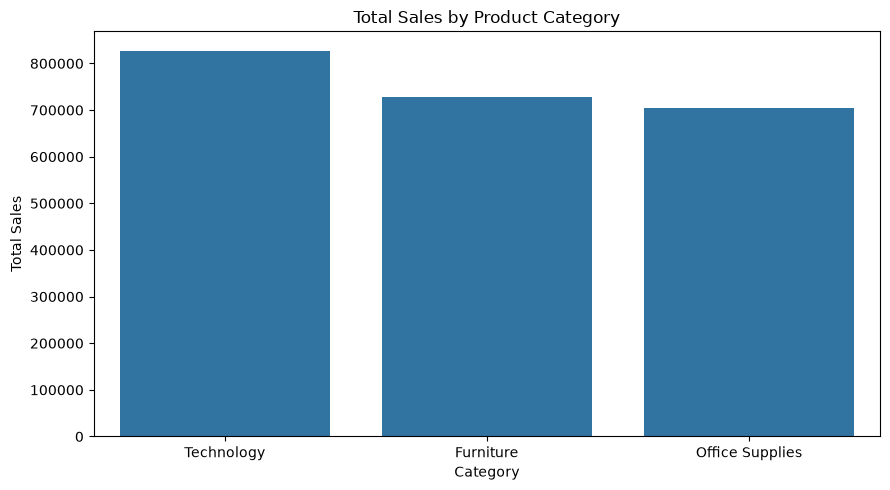

In [44]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_sales,
    x="Category",
    y="Total_Sales"
)

plt.title("Total Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sales_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

C. Monthly sales trends

Aggregate sales by month to understand how performance changes over time.

In [45]:
monthly_sales = (
    df.set_index("Order Date")["Sales"]
    .resample("MS")
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Order_Month", "Total_Sales"]

display(monthly_sales.head())

,Order_Month,Total_Sales
0,2015-01-01,14205.707
1,2015-02-01,4519.892
2,2015-03-01,55205.797
3,2015-04-01,27906.855
4,2015-05-01,23644.303


Plot the trend:

Look for seasonal patterns, growth periods, months with unusually high or low sales. Do not assume that a single increase establishes a long-term trend.

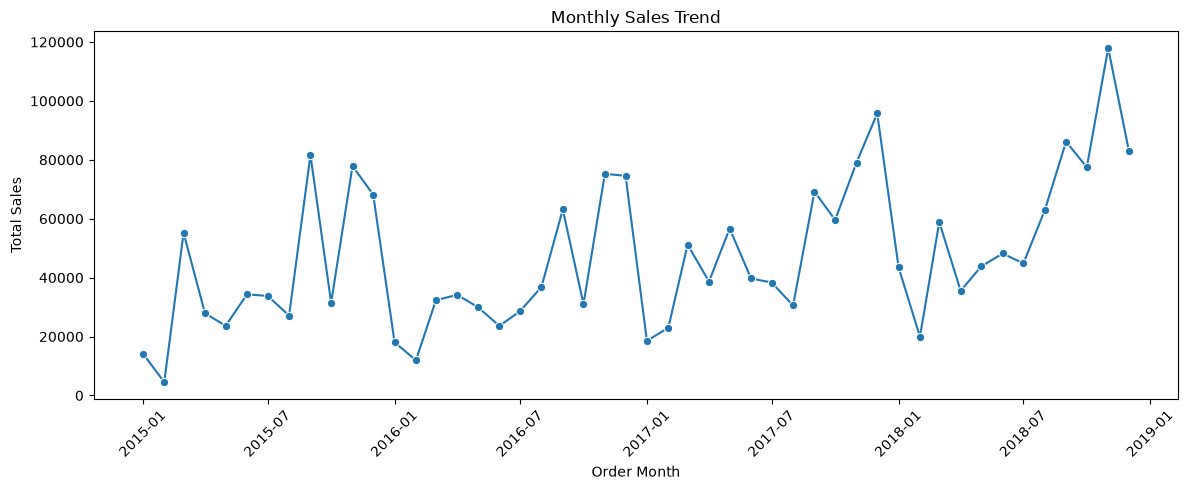

In [48]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="Order_Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Order Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

D. Regional Sales Performance:



In [50]:
regional_sales = (
    df.groupby("Region", as_index=False)
    .agg(Total_Sales=("Sales", "sum"))
    .sort_values("Total_Sales", ascending=False)
)

display(regional_sales)

,Region,Total_Sales
3,West,710219.6845
1,East,669518.7260
0,Central,492646.9132
2,South,389151.4590


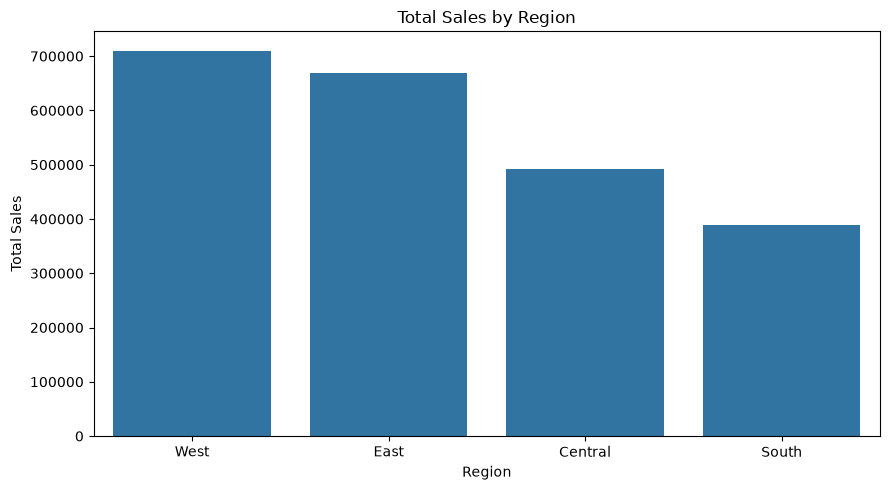

In [51]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=regional_sales,
    x="Region",
    y="Total_Sales"
)

plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sales_by_region.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

E. Top 10 products by sales

In [52]:
top_products = (
    df.groupby("Product Name", as_index=False)
    .agg(Total_Sales=("Sales", "sum"))
    .nlargest(10, "Total_Sales")
    .sort_values("Total_Sales", ascending=False)
)

display(top_products)

,Product Name,Total_Sales
404,Canon imageCLASS 2200 Advanced Copier,61599.824
649,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480
785,HON 5400 Series Task Chairs for Big and Tall,21870.576
685,GBC DocuBind TL300 Electric Binding System,19823.479
687,GBC Ibimaster 500 Manual ProClick Binding System,19024.500
804,Hewlett Packard LaserJet 3310 Copier,18839.686
786,HP Designjet T520 Inkjet Large Format Printer ...,18374.895
682,GBC DocuBind P400 Electric Binding System,17965.068
812,High Speed Automatic Electric Letter Opener,17030.312


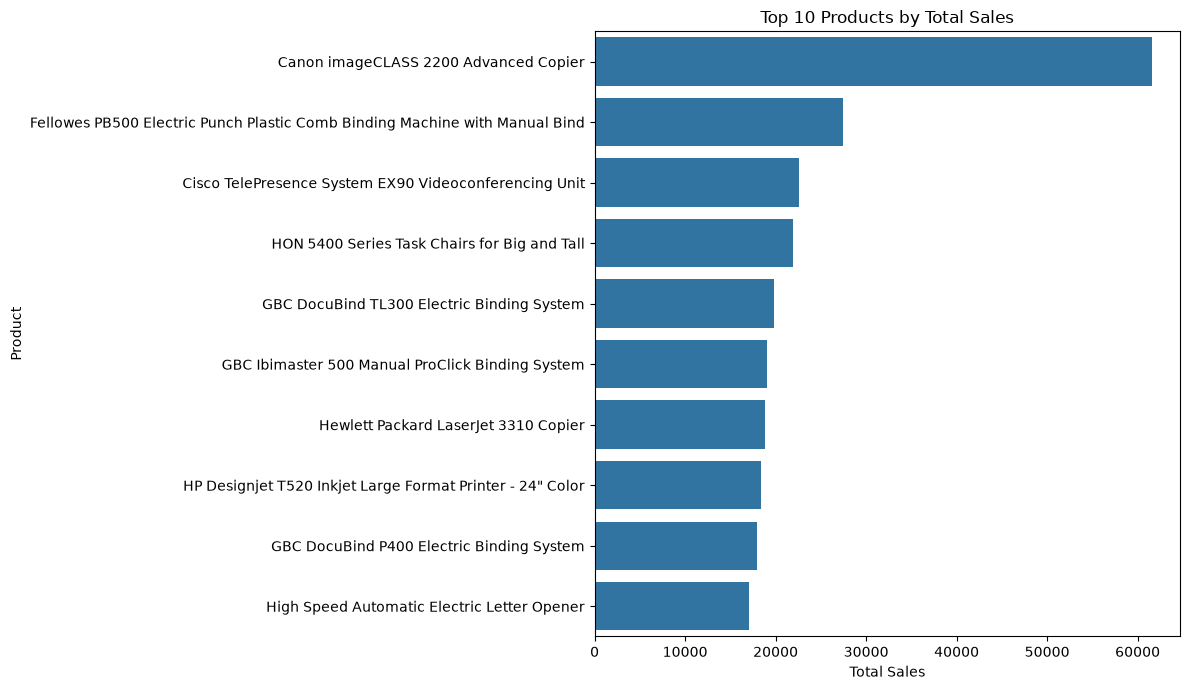

In [53]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_products,
    x="Total_Sales",
    y="Product Name"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

F. Customer segment analysis

Compare Revenue, customer count, order count across segments.

In [54]:
segment_sales = (
    df.groupby("Segment", as_index=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Unique_Customers=("Customer ID", "nunique"),
        Unique_Orders=("Order ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(segment_sales)

,Segment,Total_Sales,Unique_Customers,Unique_Orders
0,Consumer,1.148061e+06,409,2537
1,Corporate,6.884941e+05,236,1491
2,Home Office,4.249822e+05,148,894


G. Correlation and outlier investigation.

E.g Sales and Profit. 

This dataset has limited scope for meaningful correlation analysis as it only measures Sales.

Do not interpret correlations between encoded identifiers and sales as meaningful relationships. Ensure that all columns(Attribute) are in their correct data types, Postal Code should be a string not a float, Date a datetime not string or number.

In [58]:
numeric_df = df.select_dtypes(include="number")

display(numeric_df.corr())

,Sales
Sales,1.0


To investigate unusually large sales values:

Large values are not automatically outliers that should be removed. Determine whether they represent legitimate transactions.

In [59]:
display(
    df.nlargest(10, "Sales")[
        ["Order ID", "Product Name", "Category", "Region", "Sales"]
    ]
)

,Order ID,Product Name,Category,Region,Sales
2697,CA-2015-145317,Cisco TelePresence System EX90 Videoconferenci...,Technology,South,22638.480
6826,CA-2017-118689,Canon imageCLASS 2200 Advanced Copier,Technology,Central,17499.950
8153,CA-2018-140151,Canon imageCLASS 2200 Advanced Copier,Technology,West,13999.960
2623,CA-2018-127180,Canon imageCLASS 2200 Advanced Copier,Technology,East,11199.968
4190,CA-2018-166709,Canon imageCLASS 2200 Advanced Copier,Technology,East,10499.970
9039,CA-2017-117121,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Central,9892.740
4098,CA-2015-116904,Ibico EPK-21 Electric Binding System,Office Supplies,Central,9449.950
4277,US-2017-107440,"3D Systems Cube Printer, 2nd Generation, Magenta",Technology,East,9099.930
8488,CA-2017-158841,HP Designjet T520 Inkjet Large Format Printer ...,Technology,South,8749.950
6425,CA-2017-143714,Canon imageCLASS 2200 Advanced Copier,Technology,East,8399.976


8. Create a consolidated KPI summary. Summarize the main metrics in one place.

In [62]:
kpi_summary = pd.DataFrame({
    "Metric":[
        "Total Sales",
        "Distinct Orders",
        "Distinct Customers",
        "Average Sales per Row",
        "Median Sales per Row"
    ],
    "Value":[
        df["Sales"].sum(),
        df["Order ID"].nunique(),
        df["Customer ID"].nunique(),
        df["Sales"].mean(),
        df["Sales"].median()
    ]
})

display(kpi_summary)

,Metric,Value
0,Total Sales,2.261537e+06
1,Distinct Orders,4.922000e+03
2,Distinct Customers,7.930000e+02
3,Average Sales per Row,2.307691e+02
4,Median Sales per Row,5.449000e+01


Save the summary and analysis outputs:

In [65]:
kpi_summary.to_csv(
    PROJECT_DIR / "outputs" / "kpi_summary.csv",
    index=False
)

category_sales.to_csv(
    PROJECT_DIR / "outputs" / "sales_by_category.csv",
    index=False
)

monthly_sales.to_csv(
    PROJECT_DIR / "outputs" / "monthly_sales.csv",
    index=False
)

9. Save the cleaned dataset

In [66]:
CLEAN_PATH = PROJECT_DIR / "data/processed" / "sales_data_cleaned.csv"

df.to_csv(CLEAN_PATH, index=False)

print(f"Cleaned dataset saved to: {CLEAN_PATH}")

Cleaned dataset saved to: /mnt/d/DS_Course/11.Career_prep/To_Job/Projects/Data_Analyst/Sales_Dashboard/data/processed/sales_data_cleaned.csv
